In [ ]:
!pip install ortools

In [ ]:
from ortools.sat.python import cp_model
from random import randint
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (40,15)

#Data

In [ ]:
n_hospitales = 5
n_pacientes = 500
n_camas_en_hospitales = [randint(10,100) for _ in range(n_hospitales)]
print(n_camas_en_hospitales)
n_camas_total = sum(n_camas_en_hospitales)
print(n_camas_total)

#localización
pacientes_loc = [(randint(0,100),randint(0,100)) for _ in range(n_pacientes)]
print(pacientes_loc)
hospitales_loc = [(randint(0,100),randint(0,100)) for _ in range(n_hospitales)]
print(hospitales_loc)
#grado de contagio
pacientes_contagio = [randint(1,5) for _ in range(n_pacientes)]
print(pacientes_contagio)

[36, 93, 94, 60, 42]
325
[(15, 46), (54, 77), (47, 10), (14, 76), (53, 72), (93, 0), (13, 89), (87, 7), (75, 6), (100, 96), (76, 56), (37, 81), (90, 36), (65, 80), (48, 53), (7, 60), (58, 21), (67, 58), (88, 76), (91, 98), (62, 74), (79, 88), (22, 53), (94, 6), (66, 61), (38, 44), (9, 84), (4, 7), (37, 55), (16, 69), (36, 11), (27, 95), (85, 76), (63, 63), (75, 0), (93, 95), (72, 83), (98, 41), (87, 79), (34, 3), (35, 30), (52, 23), (70, 52), (57, 38), (19, 18), (4, 73), (72, 19), (62, 43), (80, 31), (77, 50), (55, 50), (72, 50), (32, 76), (59, 20), (83, 82), (18, 48), (40, 68), (29, 56), (72, 74), (33, 46), (66, 65), (16, 100), (12, 80), (67, 81), (72, 43), (55, 31), (43, 30), (36, 51), (6, 1), (46, 14), (80, 71), (79, 42), (60, 11), (2, 74), (94, 78), (21, 68), (71, 53), (6, 47), (27, 92), (63, 38), (45, 42), (27, 8), (8, 53), (78, 7), (53, 83), (98, 78), (44, 75), (50, 76), (74, 44), (45, 25), (12, 24), (93, 5), (62, 58), (39, 5), (35, 42), (84, 92), (16, 52), (52, 91), (73, 39), (1

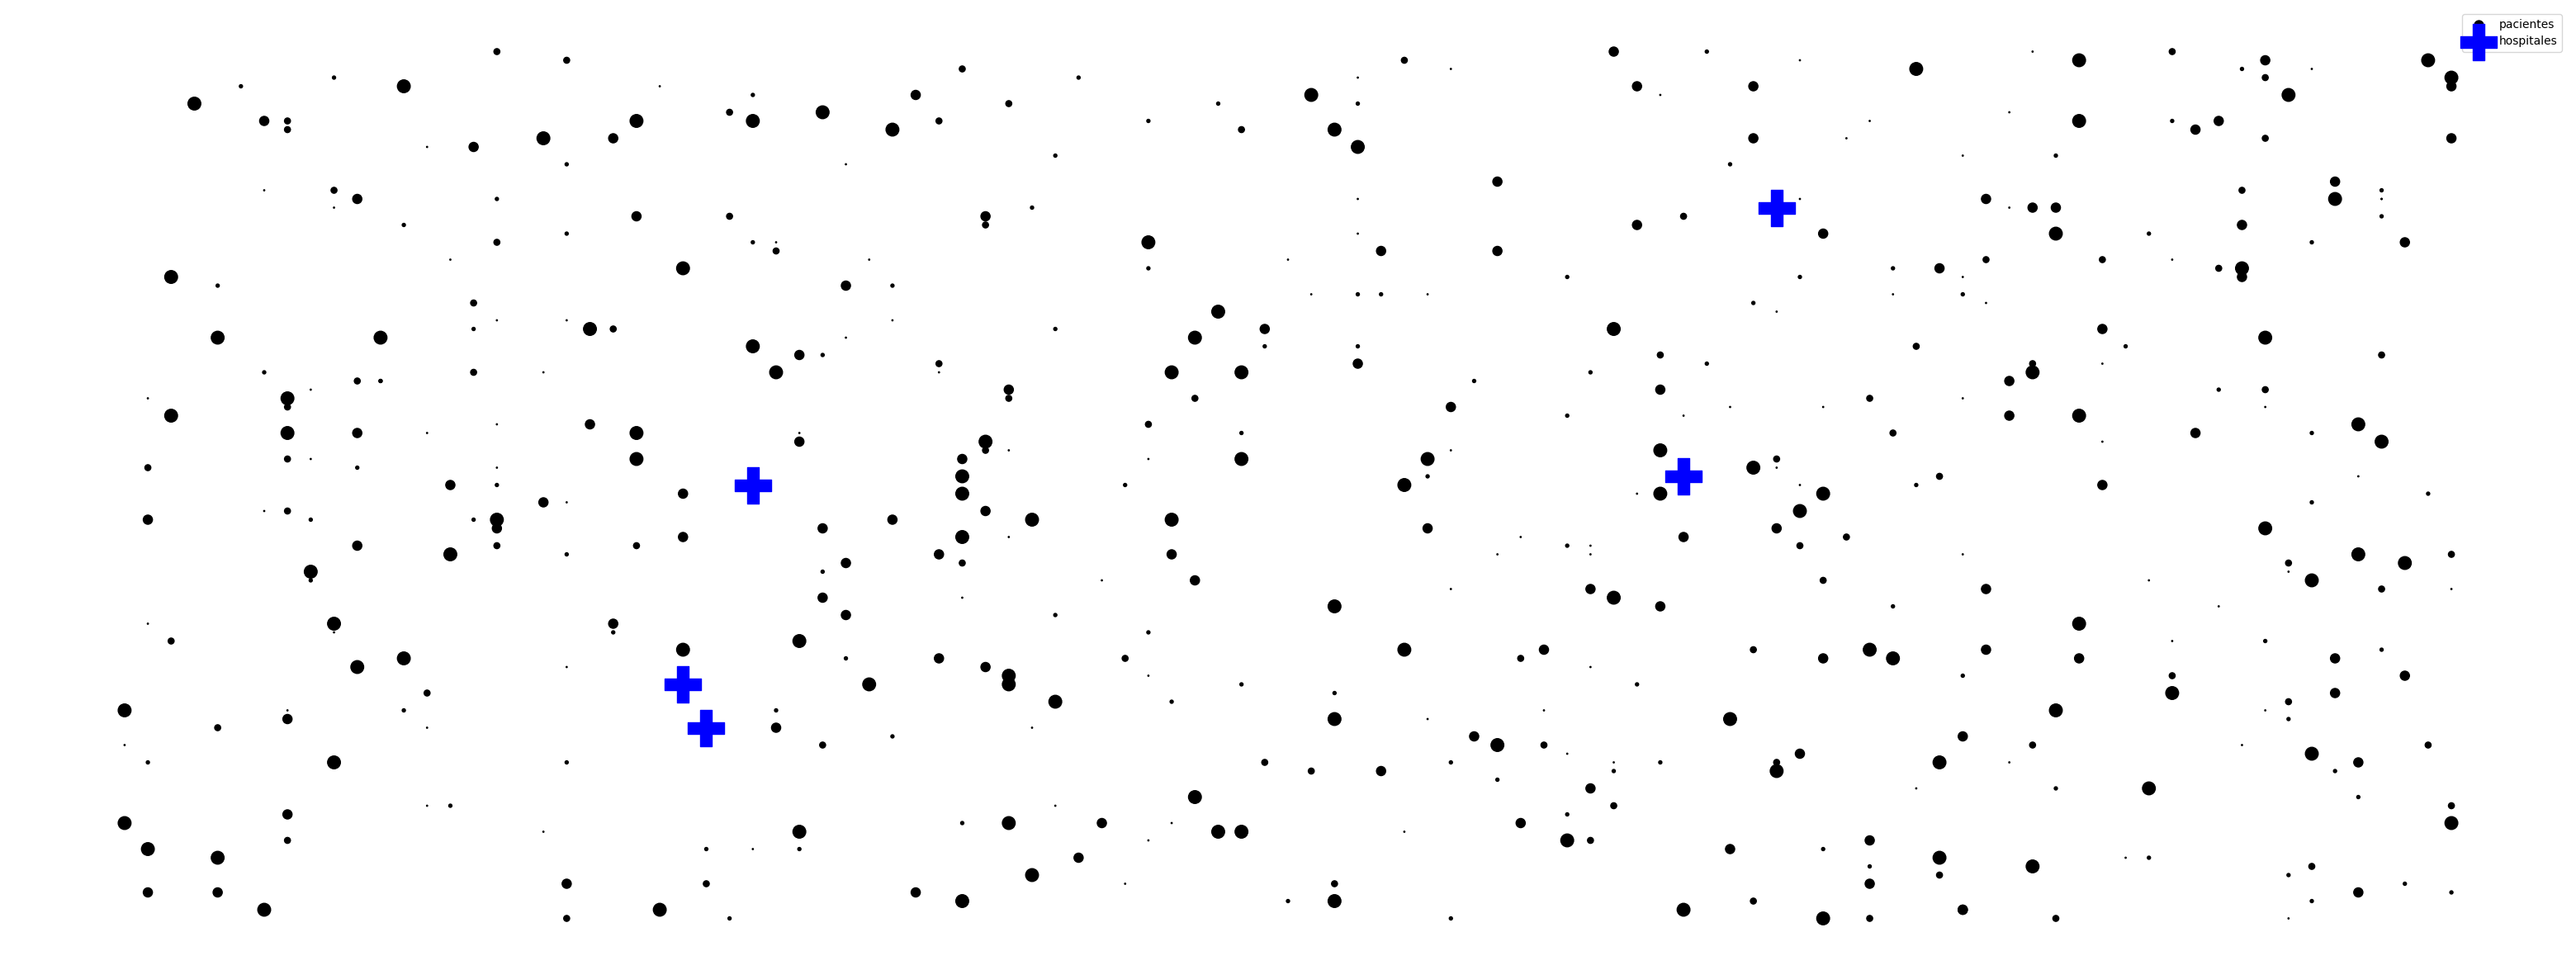

In [ ]:
#visualización
tamano_contagio = [sev**3 for sev in pacientes_contagio]
plt.scatter(*zip(*pacientes_loc), s=tamano_contagio, c='black', label='pacientes')
plt.scatter(*zip(*hospitales_loc), s=1000, c='b', marker='P', label='hospitales')
plt.legend()
plt.axis('off')
plt.show()

#CSP

In [ ]:
#crear CSP
model = cp_model.CpModel()

#variables y dominios
x = {}
for i in range(n_hospitales):
  for j in range(n_camas_en_hospitales[i]):
    for k in range(n_pacientes):
      x[(i,j,k)] = model.NewBoolVar('x_'+str(i)+'_'+str(j)+'_'+str(k))

#restricciones
##hard constraints
##There must be at most a single person in every bed.
for i in range(n_hospitales): #para cada hospital
  for j in range(n_camas_en_hospitales[i]): #para cada cama del hospital i
    model.Add(sum([x[(i,j,k)] for k in range(n_pacientes)]) <= 1)
##There must be at most a single bed assigned to every person.
for k in range(n_pacientes): #para cada paciente
  n_pacientes_camas_hospitales = []
  for i in range(n_hospitales): #para cada hospital
    n_pacientes_camas_hospitales.append(sum(x[(i,j,k)] for j in range(n_camas_en_hospitales[i]))) #sumar para todas las camas, las que tengan al paciente k
  model.Add(sum(n_pacientes_camas_hospitales) <= 1)

def dist(p1,p2):
  return int(((p1[0]-p2[0])**2+(p1[1]-p2[1])**2)**0.5)

max_dist = 0
for i in range(n_hospitales):
  for k in range(n_pacientes):
    if max_dist < dist(hospitales_loc[i], pacientes_loc[k]):
      max_dist = dist(hospitales_loc[i], pacientes_loc[k])

##soft constraints
pref = []
for i in range(n_hospitales):
  for j in range(n_camas_en_hospitales[i]):
    for k in range(n_pacientes):
      #Every sick person should be placed into a bed
      #Every person should be handled by the nearest hospital
      #Sick persons in severe condition should be handled first when there are not enough beds.
      #pref += [x[(i,j,k)] - x[(i,j,k)] * dist(pacientes_loc[k], hospitales_loc[i]) + x[(i,j,k)] * pacientes_contagio[k]]
      pref += [x[(i,j,k)] * (100 - 100 * dist(pacientes_loc[k], hospitales_loc[i]) / max_dist + 100 * pacientes_contagio[k] / 5)]
#print(pref)
model.Maximize(sum(pref))

In [ ]:
#solver
solver = cp_model.CpSolver()
status = solver.Solve(model)
if status == cp_model.OPTIMAL:
  print('Tiempo:',solver.WallTime())
  for i in range(n_hospitales):
    print('Hospital {} {} tiene {} camas'.format(i+1,hospitales_loc[i],n_camas_en_hospitales[i]))
    for j in range(n_camas_en_hospitales[i]):
      for k in range(n_pacientes):
        if solver.Value(x[(i,j,k)]):
          print('\tPaciente {} en la cama {}'.format(k+1,j+1))
    print()

Tiempo: 147.066520276
Hospital 1 (25, 22) tiene 36 camas
	Paciente 496 en la cama 1
	Paciente 441 en la cama 2
	Paciente 436 en la cama 3
	Paciente 485 en la cama 4
	Paciente 476 en la cama 5
	Paciente 442 en la cama 6
	Paciente 354 en la cama 7
	Paciente 420 en la cama 8
	Paciente 440 en la cama 9
	Paciente 312 en la cama 10
	Paciente 353 en la cama 11
	Paciente 427 en la cama 12
	Paciente 495 en la cama 13
	Paciente 330 en la cama 14
	Paciente 463 en la cama 15
	Paciente 387 en la cama 16
	Paciente 473 en la cama 17
	Paciente 481 en la cama 18
	Paciente 409 en la cama 19
	Paciente 310 en la cama 20
	Paciente 314 en la cama 21
	Paciente 332 en la cama 22
	Paciente 416 en la cama 23
	Paciente 299 en la cama 24
	Paciente 389 en la cama 25
	Paciente 295 en la cama 26
	Paciente 370 en la cama 27
	Paciente 394 en la cama 28
	Paciente 365 en la cama 29
	Paciente 294 en la cama 30
	Paciente 452 en la cama 31
	Paciente 307 en la cama 32
	Paciente 324 en la cama 33
	Paciente 417 en la cama 34


In [ ]:
plot_lineas = [[] for _ in range(n_hospitales)]
for i in range(n_hospitales):
  for j in range(n_camas_en_hospitales[i]):
    for k in range(n_pacientes):
      if solver.Value(x[(i,j,k)]):
        linea_abcisa = [hospitales_loc[i][0], pacientes_loc[k][0]]
        linea_ordenada = [hospitales_loc[i][1], pacientes_loc[k][1]]
        plot_lineas[i].append([linea_abcisa,linea_ordenada])

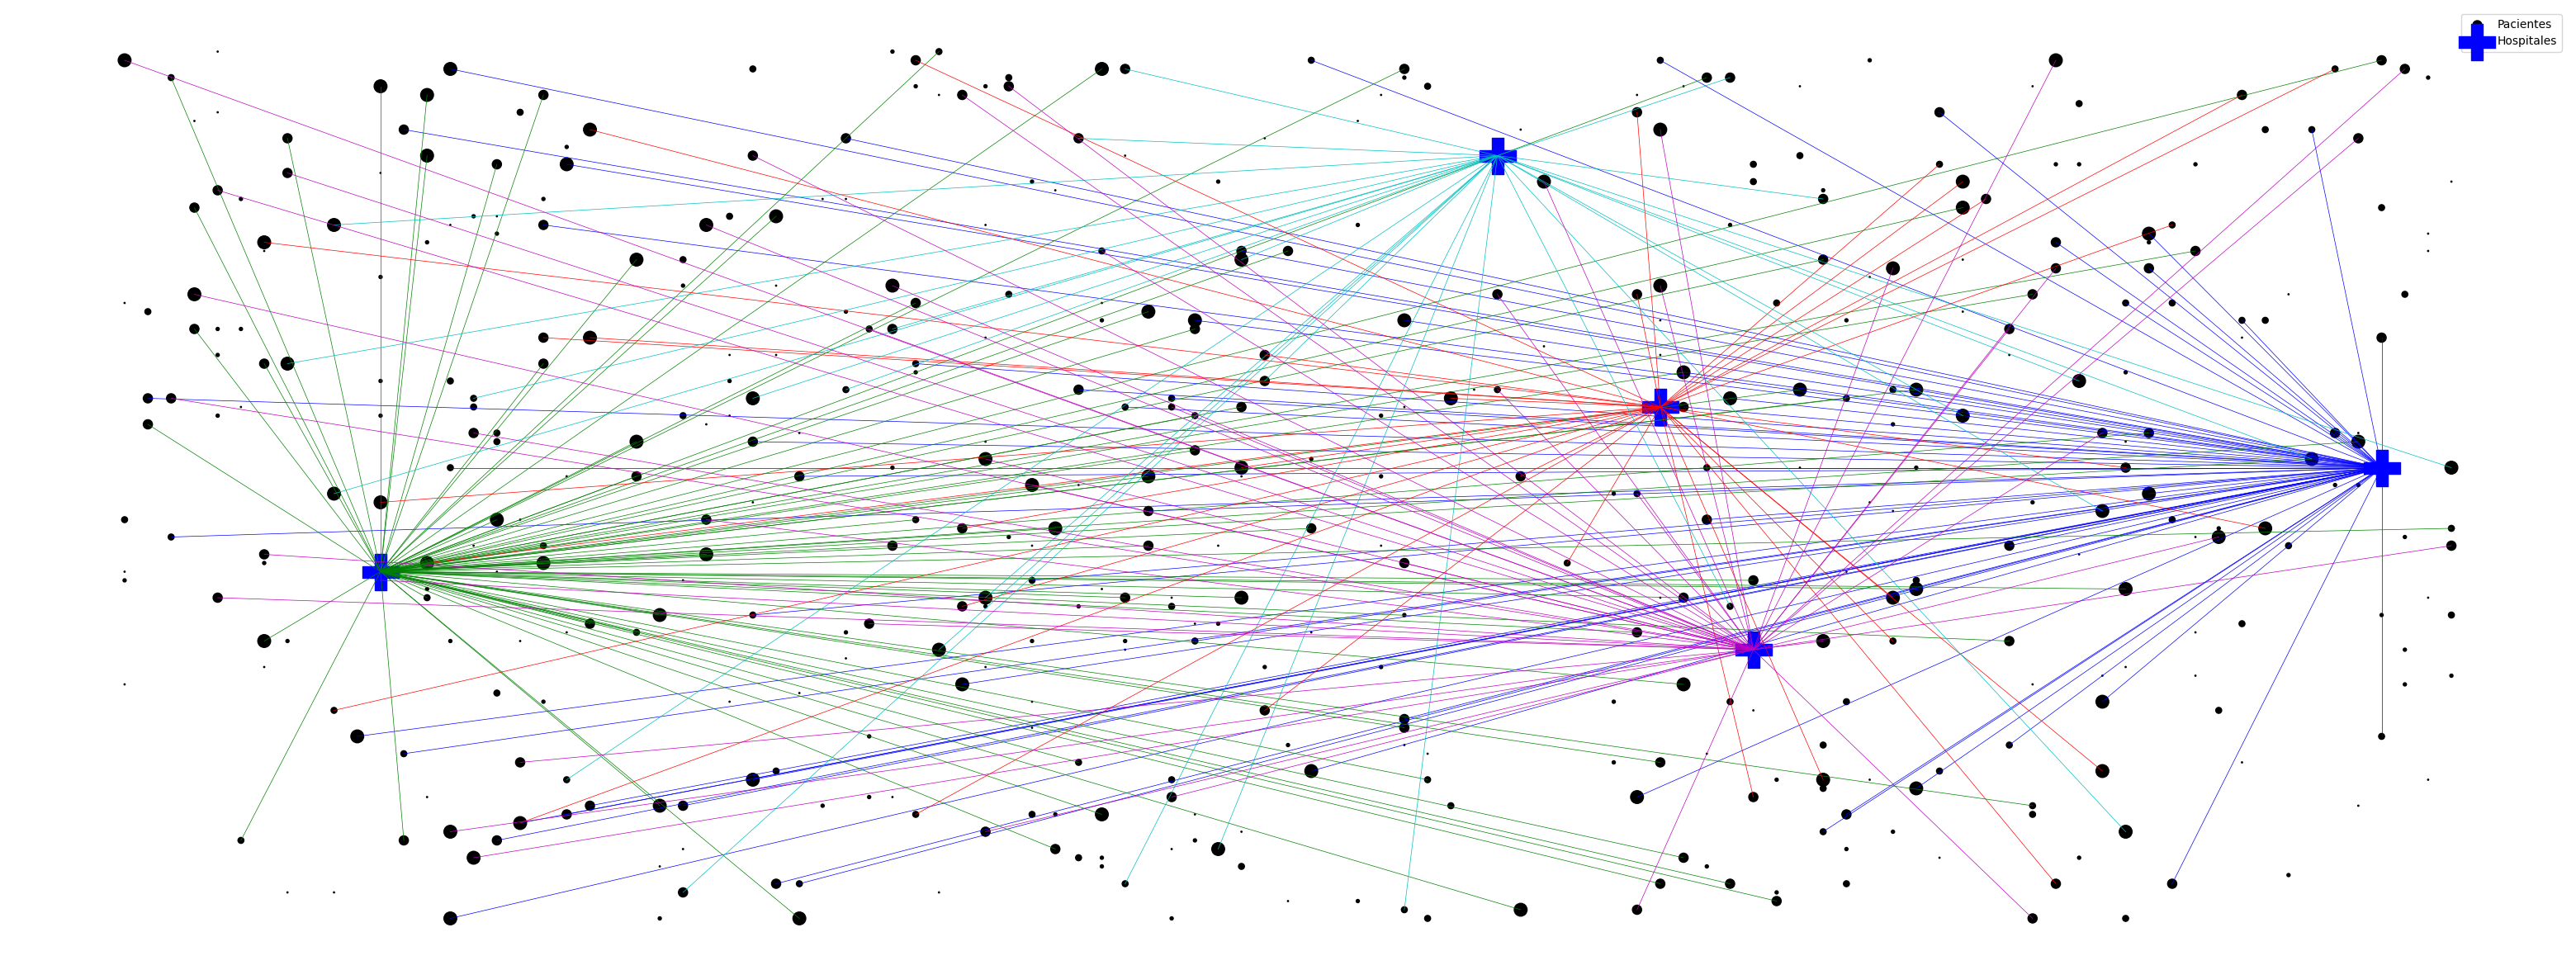

In [ ]:
from itertools import cycle

plt.scatter(*zip(*pacientes_loc), s=tamano_contagio, color='black', label='Pacientes')
plt.scatter(*zip(*hospitales_loc), s=1000, color='blue', marker='P', label='Hospitales')
#plotear líneas de hospitales por colores
colores = cycle('bgrcmk')
for i in range(n_hospitales):
  c = next(colores)
  for (x_,y_) in plot_lineas[i]:
    plt.plot(x_, y_, c=c, linewidth=.5)
plt.legend()
plt.axis('off')
plt.show()